In [1]:
%pip install pyautogui mss opencv-python numpy matplotlib pynput


   ---------------------------------------- 0/2 [pynput]
   ---------------------------------------- 2/2 [mss]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:

import time
import cv2
import numpy as np
import pyautogui as pyg
import mss
import matplotlib.pyplot as plt
from pynput import keyboard

pyg.PAUSE = 0.05
pyg.FAILSAFE = True

print("套件載入成功！")
print("螢幕解析度：", pyg.size())


套件載入成功！
螢幕解析度： Size(width=1920, height=1080)


截圖尺寸： (1080, 1920, 3)


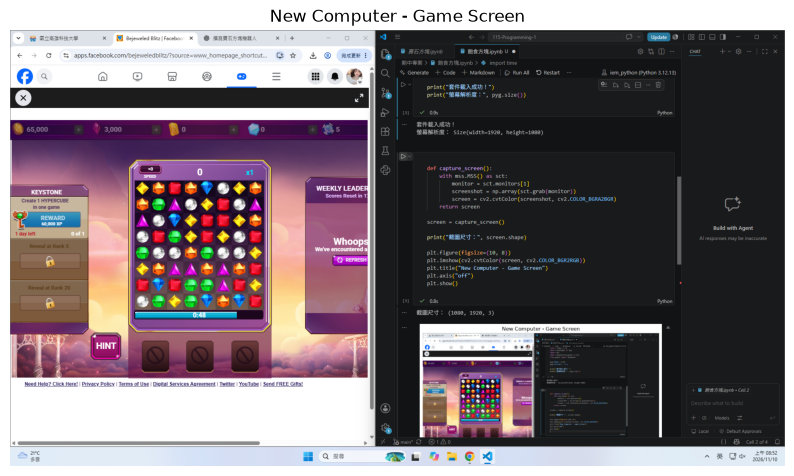

In [4]:

def capture_screen():
    with mss.MSS() as sct:
        monitor = sct.monitors[1]
        screenshot = np.array(sct.grab(monitor))
        screen = cv2.cvtColor(screenshot, cv2.COLOR_BGRA2BGR)
    return screen

screen = capture_screen()

print("截圖尺寸：", screen.shape)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(screen, cv2.COLOR_BGR2RGB))
plt.title("New Computer - Game Screen")
plt.axis("off")
plt.show()


In [5]:

screen = capture_screen()

roi = cv2.selectROI(
    "Select Gem Board - Press ENTER",
    screen,
    showCrosshair=True,
    fromCenter=False
)

cv2.destroyAllWindows()

board_x, board_y, board_w, board_h = map(int, roi)

if board_w == 0 or board_h == 0:
    raise ValueError("沒有選到棋盤，請重新執行！")

cell_w = board_w / 8
cell_h = board_h / 8

print("棋盤 X：", board_x)
print("棋盤 Y：", board_y)
print("棋盤寬度：", board_w)
print("棋盤高度：", board_h)
print("每格寬度：", cell_w)
print("每格高度：", cell_h)


棋盤 X： 307
棋盤 Y： 372
棋盤寬度： 323
棋盤高度： 326
每格寬度： 40.375
每格高度： 40.75


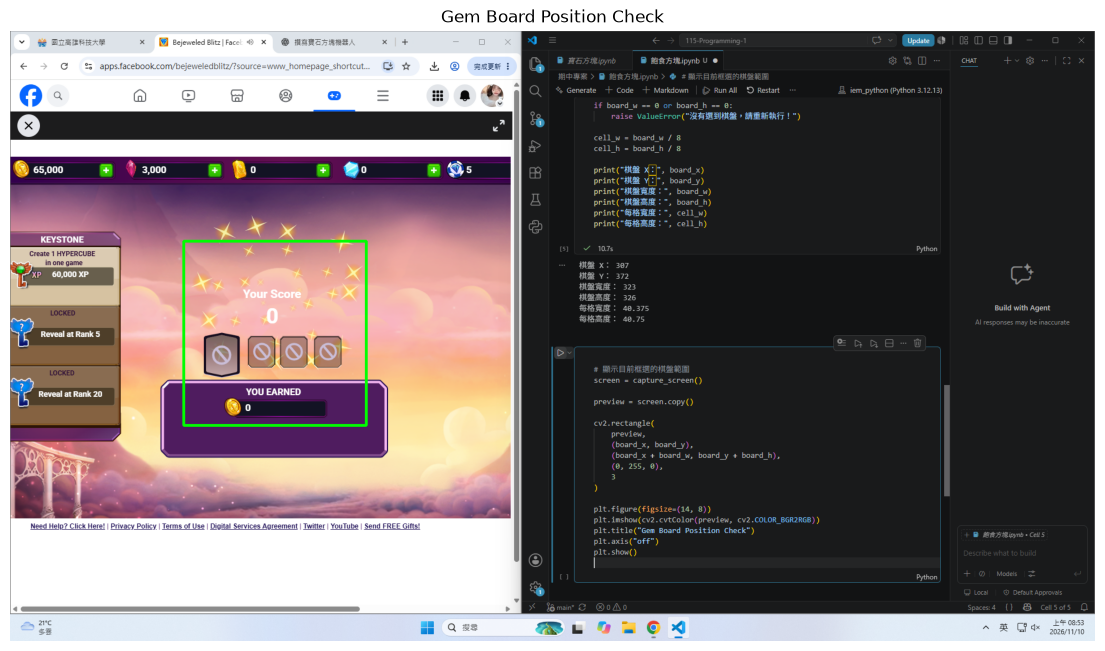

In [6]:

# 顯示目前框選的棋盤範圍
screen = capture_screen()

preview = screen.copy()

cv2.rectangle(
    preview,
    (board_x, board_y),
    (board_x + board_w, board_y + board_h),
    (0, 255, 0),
    3
)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("Gem Board Position Check")
plt.axis("off")
plt.show()


In [7]:

# GEM BOT - 滑鼠拖曳測試

import time
import pyautogui as pyg

def drag_gem(r1, c1, r2, c2):
    cell_w = board_w / 8
    cell_h = board_h / 8

    start_x = int(board_x + (c1 + 0.5) * cell_w)
    start_y = int(board_y + (r1 + 0.5) * cell_h)

    end_x = int(board_x + (c2 + 0.5) * cell_w)
    end_y = int(board_y + (r2 + 0.5) * cell_h)

    print("起點：", start_x, start_y)
    print("終點：", end_x, end_y)

    pyg.moveTo(start_x, start_y, duration=0.3)
    pyg.mouseDown()

    try:
        time.sleep(0.3)
        pyg.moveTo(end_x, end_y, duration=0.5)
        time.sleep(0.3)
    finally:
        pyg.mouseUp()

print("3 秒後開始，請切換到遊戲畫面！")
time.sleep(3)

# 第 3 列第 3 欄 → 第 3 列第 4 欄
drag_gem(2, 2, 2, 3)

print("測試完成！")


3 秒後開始，請切換到遊戲畫面！
起點： 407 473
終點： 448 473
測試完成！


In [8]:

# ==========================================
# GEM BOT - 8x8 寶石顏色辨識
# ==========================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

def detect_gem_color(patch):
    if patch is None or patch.size == 0:
        return "?"

    hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
    h, s, v = np.median(hsv.reshape(-1, 3), axis=0)

    if s < 55 and v > 100:
        return "W"
    elif h < 8 or h >= 170:
        return "R"
    elif h < 20:
        return "O"
    elif h < 36:
        return "Y"
    elif h < 85:
        return "G"
    elif h < 125:
        return "B"
    elif h < 170:
        return "P"

    return "?"

def read_game_board():
    screen = capture_screen()
    board = []

    cell_w = board_w / 8
    cell_h = board_h / 8

    for r in range(8):
        row = []

        for c in range(8):
            cx = int(board_x + (c + 0.5) * cell_w)
            cy = int(board_y + (r + 0.5) * cell_h)

            patch = screen[
                cy-6:cy+6,
                cx-6:cx+6
            ]

            row.append(detect_gem_color(patch))

        board.append(row)

    return board

# 等待遊戲畫面穩定
print("3 秒後開始辨識棋盤")
time.sleep(3)

board = read_game_board()

print("\n目前辨識到的 8x8 棋盤：")
for row in board:
    print(" ".join(row))


3 秒後開始辨識棋盤

目前辨識到的 8x8 棋盤：
W B G B R P O Y
Y G Y O R O Y G
Y R B G Y G B P
P R R B Y B W P
P G O P O B B Y
G G B G W Y O R
G R G P Y R Y B
B B R W R O O G


In [10]:

# ==========================================
# GEM BOT - SMART SOLVER
# 尋找有效交換與立即消除數
# ==========================================

import numpy as np

def find_matches(board):
    matches = set()

    # 橫向連續三顆以上
    for r in range(8):
        c = 0
        while c < 8:
            start = c
            color = board[r][c]

            while c < 8 and board[r][c] == color:
                c += 1

            if color != "?" and c - start >= 3:
                for k in range(start, c):
                    matches.add((r, k))

    # 縱向連續三顆以上
    for c in range(8):
        r = 0
        while r < 8:
            start = r
            color = board[r][c]

            while r < 8 and board[r][c] == color:
                r += 1

            if color != "?" and r - start >= 3:
                for k in range(start, r):
                    matches.add((k, c))

    return matches


def get_valid_moves(board):
    moves = []

    for r in range(8):
        for c in range(8):

            # 只檢查右邊與下方
            for dr, dc in [(0, 1), (1, 0)]:
                nr = r + dr
                nc = c + dc

                if nr >= 8 or nc >= 8:
                    continue

                test = [row.copy() for row in board]

                test[r][c], test[nr][nc] = (
                    test[nr][nc], test[r][c]
                )

                matches = find_matches(test)

                # 確認消除包含交換位置
                if matches and (
                    (r, c) in matches or
                    (nr, nc) in matches
                ):
                    moves.append({
                        "from": (r, c),
                        "to": (nr, nc),
                        "immediate": len(matches)
                    })

    return sorted(
        moves,
        key=lambda x: x["immediate"],
        reverse=True
    )


# ---------- 分析最新棋盤 ----------
board = read_game_board()
moves = get_valid_moves(board)

print("找到有效走法：", len(moves), "種")

print("\n最佳 5 個走法：")

for i, move in enumerate(moves[:5], 1):
    r1, c1 = move["from"]
    r2, c2 = move["to"]

    print(
        f"{i}. 第 {r1+1} 列第 {c1+1} 欄"
        f" → 第 {r2+1} 列第 {c2+1} 欄"
        f" | 立即消除 {move['immediate']} 顆"
    )


找到有效走法： 14 種

最佳 5 個走法：
1. 第 7 列第 6 欄 → 第 8 列第 6 欄 | 立即消除 6 顆
2. 第 7 列第 3 欄 → 第 7 列第 4 欄 | 立即消除 4 顆
3. 第 1 列第 3 欄 → 第 1 列第 4 欄 | 立即消除 3 顆
4. 第 3 列第 3 欄 → 第 4 列第 3 欄 | 立即消除 3 顆
5. 第 3 列第 4 欄 → 第 3 列第 5 欄 | 立即消除 3 顆


In [11]:

# ==========================================
# GEM BOT - BEST MOVE TEST
# 自動尋找並執行最佳走法
# ==========================================

import time
import pyautogui as pyg

def execute_best_move():

    # 重新讀取最新棋盤
    board = read_game_board()

    # 尋找有效走法
    moves = get_valid_moves(board)

    if not moves:
        print("目前沒有有效走法")
        return

    # 選擇立即消除最多的走法
    best = moves[0]

    r1, c1 = best["from"]
    r2, c2 = best["to"]

    print("最佳走法：")
    print(
        f"第 {r1+1} 列第 {c1+1} 欄"
        f" → 第 {r2+1} 列第 {c2+1} 欄"
    )
    print("預計立即消除：", best["immediate"], "顆")

    # 計算滑鼠座標
    sx = int(board_x + (c1 + 0.5) * cell_w)
    sy = int(board_y + (r1 + 0.5) * cell_h)

    ex = int(board_x + (c2 + 0.5) * cell_w)
    ey = int(board_y + (r2 + 0.5) * cell_h)

    print("起點：", sx, sy)
    print("終點：", ex, ey)

    # 真實滑鼠操作
    pyg.moveTo(sx, sy, duration=0.3)
    pyg.mouseDown()

    try:
        time.sleep(0.3)
        pyg.moveTo(ex, ey, duration=0.5)
        time.sleep(0.3)
    finally:
        pyg.mouseUp()

    print("最佳走法執行完成！")


print("3 秒後開始，請切換到遊戲畫面！")
time.sleep(3)

execute_best_move()


3 秒後開始，請切換到遊戲畫面！
最佳走法：
第 7 列第 6 欄 → 第 8 列第 6 欄
預計立即消除： 6 顆
起點： 529 636
終點： 529 677
最佳走法執行完成！


In [21]:

# ==========================================================
# GEM BOT 4.1 - INSTANT START
# 寶石方塊自動操作機器人
#
# 程式功能：
# 1. 自動辨識遊戲中的 8×8 寶石棋盤
# 2. 分析棋盤並找出可以消除最多寶石的交換方式
# 3. 使用滑鼠自動拖曳寶石，完成交換動作
# 4. 持續執行 60 秒，並支援 ESC 暫停與恢復
# 5. 結束後統計交換次數及預計消除數量
#
# 注意：
# 本程式需要事先執行棋盤辨識及走法分析程式，
# 以取得 read_game_board()、get_valid_moves()
# 等函數，以及棋盤位置相關參數。
# ==========================================================


# ==========================================================
# 第一部分：匯入所需套件
# ==========================================================

# time：控制程式等待時間，以及計算執行時間
import time

# threading：建立事件物件，用來控制暫停與恢復
import threading

# pyautogui：模擬滑鼠移動、按下與放開等操作
import pyautogui as pyg

# pynput：監聽鍵盤按鍵，讓使用者透過 ESC 控制程式
from pynput import keyboard


# ==========================================================
# 第二部分：設定機器人的執行時間與操作速度
# ==========================================================

# 設定機器人的目標執行時間為 60 秒
RUN_SECONDS = 60

# 滑鼠移動到指定寶石位置所需的時間（秒）
MOVE_TO_START = 0.08

# 滑鼠按住寶石後，拖曳到另一格所需的時間（秒）
DRAG_DURATION = 0.15

# 滑鼠按住寶石，以及拖曳完成後的停留時間（秒）
HOLD_TIME = 0.08

# 每次交換完成後，等待遊戲消除動畫的時間（秒）
ANIMATION_WAIT = 0.18

# 設定 PyAutoGUI 每次操作後的預設等待時間
# 數值越小，滑鼠指令之間的間隔越短
pyg.PAUSE = 0.01

# 啟用安全保護機制
# 當滑鼠移動到螢幕左上角時，可觸發緊急停止
pyg.FAILSAFE = True


# ==========================================================
# 第三部分：確認必要函數與棋盤參數是否存在
# ==========================================================

# 建立必要函數與變數的名稱清單
# 這些內容必須在前面的程式中先完成定義
required = [
    "read_game_board",   # 讀取並辨識目前的寶石棋盤
    "get_valid_moves",   # 分析棋盤中所有有效交換方式
    "board_x",           # 棋盤左上角的 X 座標
    "board_y",           # 棋盤左上角的 Y 座標
    "board_w",           # 棋盤總寬度
    "board_h"            # 棋盤總高度
]

# globals() 用來取得目前程式已定義的全域名稱
# 透過清單生成式，找出尚未定義的必要項目
missing = [x for x in required if x not in globals()]

# 如果有缺少的項目，就顯示錯誤並停止執行
# 避免機器人在資料不完整的情況下繼續操作
if missing:
    raise NameError("缺少必要項目：" + ", ".join(missing))


# ==========================================================
# 第四部分：建立 ESC 鍵盤監聽功能
# ==========================================================

# 建立事件物件，用來記錄機器人是否處於執行狀態
pause_event = threading.Event()

# 將事件設定為 True，表示程式一開始可以正常執行
pause_event.set()

# 記錄目前被按住的按鍵
# 避免長按 ESC 時，重複觸發暫停與恢復
pressed_keys = set()


# 當使用者按下鍵盤按鍵時，執行此函數
def on_key_press(key):

    # 如果按鍵已經被記錄，表示尚未放開
    # 因此不重複處理
    if key in pressed_keys:
        return

    # 將目前按下的按鍵加入集合
    pressed_keys.add(key)

    # 判斷使用者是否按下 ESC
    if key == keyboard.Key.esc:

        # 如果機器人目前正在執行
        if pause_event.is_set():

            # 清除事件狀態，使機器人進入暫停模式
            pause_event.clear()

            print("\n[ESC] 已暫停")

        else:

            # 如果目前已暫停，就重新開啟執行狀態
            pause_event.set()

            print("\n[ESC] 已恢復")


# 當使用者放開鍵盤按鍵時，執行此函數
def on_key_release(key):

    # 從按鍵集合中移除已放開的按鍵
    pressed_keys.discard(key)


# 建立鍵盤監聽器
# on_press：按下按鍵時執行的函數
# on_release：放開按鍵時執行的函數
listener = keyboard.Listener(
    on_press=on_key_press,
    on_release=on_key_release
)

# 啟動鍵盤監聽器，開始偵測 ESC 按鍵
listener.start()


# ==========================================================
# 第五部分：建立執行時間計算功能
# ==========================================================

# 記錄機器人累積執行的時間
active_elapsed = 0.0

# 記錄上一次更新時間的時間點
# monotonic() 適合用來測量經過的時間
last_tick = time.monotonic()


# 更新機器人累積執行時間
def update_clock():

    # 使用 global 讓函數能修改外部的計時變數
    global active_elapsed, last_tick

    # 取得目前時間
    now = time.monotonic()

    # 只有在機器人處於執行狀態時
    # 才將經過的時間加入累積執行時間
    if pause_event.is_set():
        active_elapsed += now - last_tick

    # 更新上一次記錄的時間點
    last_tick = now

    # 回傳目前累積的執行時間
    return active_elapsed


# 判斷機器人是否處於暫停狀態
def wait_if_paused():

    global last_tick

    # 如果事件狀態為 False，代表機器人已暫停
    while not pause_event.is_set():

        # 放開滑鼠按鍵，避免暫停時持續按住
        pyg.mouseUp()

        # 更新時間點，避免暫停期間的時間被累積
        last_tick = time.monotonic()

        # 每隔 0.05 秒檢查一次是否恢復
        time.sleep(0.05)

    # 恢復執行時，重新設定計時起點
    last_tick = time.monotonic()


# 建立可以配合 ESC 暫停的等待函數
def safe_wait(seconds):

    # 計算預計結束等待的時間點
    end = time.monotonic() + seconds

    # 在指定等待時間尚未結束前，持續執行
    while time.monotonic() < end:

        # 檢查是否被使用者暫停
        wait_if_paused()

        # 更新機器人的累積執行時間
        update_clock()

        # 短暫等待，避免程式持續占用處理器
        time.sleep(0.02)


# ==========================================================
# 第六部分：建立寶石自動交換功能
# ==========================================================

# r1、c1：起始寶石的列與欄
# r2、c2：目標寶石的列與欄
# 注意：程式中的列與欄從 0 開始計算
def drag_gem_auto(r1, c1, r2, c2):

    # 因為棋盤是 8×8，所以將總寬度與高度各除以 8
    # 計算每一格寶石的實際大小
    cw = board_w / 8
    ch = board_h / 8

    # 計算起始寶石中心點的螢幕 X、Y 座標
    # 加上 0.5 是為了讓滑鼠移動到格子的中心
    sx = int(board_x + (c1 + 0.5) * cw)
    sy = int(board_y + (r1 + 0.5) * ch)

    # 計算目標寶石中心點的螢幕 X、Y 座標
    ex = int(board_x + (c2 + 0.5) * cw)
    ey = int(board_y + (r2 + 0.5) * ch)

    # 將滑鼠移動到起始寶石的中心
    pyg.moveTo(sx, sy, duration=MOVE_TO_START)

    # 按下滑鼠左鍵，模擬抓取寶石
    pyg.mouseDown()

    try:

        # 稍微停留，確保遊戲偵測到滑鼠按下
        time.sleep(HOLD_TIME)

        # 保持按住滑鼠，將寶石拖曳至目標位置
        pyg.moveTo(ex, ey, duration=DRAG_DURATION)

        # 拖曳完成後稍微停留
        time.sleep(HOLD_TIME)

    finally:

        # 無論拖曳過程是否發生例外
        # 都會放開滑鼠，避免滑鼠持續處於按下狀態
        pyg.mouseUp()


# ==========================================================
# 第七部分：初始化機器人的統計資料
# ==========================================================

# 記錄成功送出多少次寶石交換指令
moves_done = 0

# 累積各次走法預計立即消除的寶石數量
immediate_total = 0

# 記錄找不到有效交換方式的次數
no_move_count = 0

# 記錄程式是否被使用者手動中斷
interrupted = False


# 顯示機器人啟動訊息
print("GEM BOT 4.1 立即啟動！")
print("ESC：暫停 / 再按一次恢復")


# ==========================================================
# 第八部分：執行寶石方塊自動操作
# ==========================================================

try:

    # 記錄程式開始執行的時間點
    last_tick = time.monotonic()

    # 使用無限迴圈持續執行
    # 直到累積執行時間達到 60 秒才停止
    while True:

        # 每次執行前先確認是否處於暫停狀態
        wait_if_paused()

        # 如果累積執行時間達到設定秒數
        # 使用 break 離開迴圈
        if update_clock() >= RUN_SECONDS:
            break

        # 重新擷取遊戲畫面，辨識目前的 8×8 棋盤
        board = read_game_board()

        # 如果無法取得棋盤資料
        # 等待 0.15 秒後重新嘗試
        if board is None:
            safe_wait(0.15)
            continue

        # 分析目前棋盤中所有可以形成消除的交換方式
        moves = get_valid_moves(board)

        # 如果找不到任何有效走法
        if not moves:

            # 記錄找不到走法的次數
            no_move_count += 1

            # 稍微等待，讓遊戲畫面有時間更新
            safe_wait(0.15)

            # continue：跳過本次迴圈剩餘內容
            # 回到迴圈開頭重新辨識棋盤
            continue

        # 選擇排序後的第一個走法
        # 前面的 get_valid_moves() 已依立即消除數排序
        best = moves[0]

        # 取得最佳走法的起點與終點
        r1, c1 = best["from"]
        r2, c2 = best["to"]

        # 執行滑鼠交換前，再次確認暫停狀態
        wait_if_paused()

        # 呼叫滑鼠拖曳函數，交換兩顆相鄰寶石
        drag_gem_auto(r1, c1, r2, c2)

        # 完成一次交換指令後，將交換次數加 1
        moves_done += 1

        # 累積這次走法預計立即消除的寶石數量
        immediate_total += best["immediate"]

        # 顯示目前交換的起點、終點與預計消除數量
        # 因為程式索引從 0 開始，所以顯示時加 1
        print(
            f"第{moves_done}次："
            f"({r1+1},{c1+1})→({r2+1},{c2+1}) "
            f"消除{best['immediate']}顆"
        )

        # 等待遊戲完成寶石交換與消除動畫
        # 避免太早辨識到尚未更新完成的棋盤
        safe_wait(ANIMATION_WAIT)


# ==========================================================
# 第九部分：處理使用者中斷
# ==========================================================

# 如果使用者在 Notebook 中手動中斷程式
# 就會執行此區塊
except KeyboardInterrupt:

    interrupted = True

    print("\n使用者中斷")


# ==========================================================
# 第十部分：結束程式並顯示統計報告
# ==========================================================

# finally：無論程式正常結束或被中斷
# 都會執行此區塊
finally:

    # 確保滑鼠左鍵已放開
    pyg.mouseUp()

    # 停止鍵盤監聽器，避免持續監聽 ESC
    listener.stop()

    # 取得最後累積的執行時間
    elapsed = update_clock()

    # 顯示執行結果
    print("\n========== GEM BOT 4.1 REPORT ==========")

    # 顯示機器人的累積執行時間
    print("執行時間：", round(elapsed, 2), "秒")

    # 顯示總共送出的寶石交換指令次數
    print("交換次數：", moves_done)

    # 顯示所有走法的預計立即消除數量總和
    # 此數值是演算法預測值，不代表實際遊戲得分
    print("預計消除數：", immediate_total)

    # 顯示找不到有效交換方式的次數
    print("無有效走法次數：", no_move_count)

    # 顯示程式是被使用者中斷，還是正常結束
    print("執行狀態：", "中斷" if interrupted else "結束")


GEM BOT 4.1 立即啟動！
ESC：暫停 / 再按一次恢復
第1次：(3,5)→(4,5) 消除47顆
第2次：(5,5)→(5,6) 消除7顆
第3次：(2,4)→(2,5) 消除10顆
第4次：(1,4)→(2,4) 消除3顆
第5次：(1,6)→(2,6) 消除7顆
第6次：(2,5)→(2,6) 消除6顆
第7次：(2,7)→(2,8) 消除9顆
第8次：(1,7)→(2,7) 消除3顆
第9次：(3,8)→(4,8) 消除3顆
第10次：(4,2)→(4,3) 消除6顆
第11次：(3,1)→(3,2) 消除8顆
第12次：(5,1)→(6,1) 消除9顆
第13次：(1,2)→(1,3) 消除6顆
第14次：(4,2)→(4,3) 消除7顆
第15次：(6,5)→(6,6) 消除6顆
第16次：(2,3)→(3,3) 消除6顆
第17次：(3,4)→(4,4) 消除6顆
第18次：(5,6)→(6,6) 消除10顆
第19次：(1,4)→(2,4) 消除7顆
第20次：(2,7)→(2,8) 消除6顆
第21次：(7,7)→(7,8) 消除7顆
第22次：(1,5)→(2,5) 消除13顆
第23次：(5,6)→(6,6) 消除9顆
第24次：(3,7)→(3,8) 消除12顆
第25次：(2,6)→(2,7) 消除3顆
第26次：(6,6)→(7,6) 消除8顆
第27次：(1,6)→(1,7) 消除3顆
第28次：(8,4)→(8,5) 消除6顆
第29次：(1,1)→(1,2) 消除9顆
第30次：(6,8)→(7,8) 消除9顆
第31次：(3,3)→(4,3) 消除7顆
第32次：(3,3)→(3,4) 消除6顆
第33次：(1,3)→(1,4) 消除6顆
第34次：(1,2)→(2,2) 消除3顆
第35次：(1,2)→(2,2) 消除3顆
第36次：(1,5)→(2,5) 消除3顆
第37次：(5,5)→(6,5) 消除6顆
第38次：(1,4)→(2,4) 消除9顆
第39次：(2,6)→(2,7) 消除26顆
第40次：(1,5)→(2,5) 消除4顆
第41次：(3,5)→(3,6) 消除3顆
第42次：(4,5)→(5,5) 消除11顆
第43次：(1,5)→(2,5) 消除3顆
第44次：(2,8)→(3,8) 消除8顆
